**Exploratory Data Analysis (EDA) and Preprocessing**

*Workflow*

1.Load the processed dataset.

2.Descriptive analysis

3.Data visualization.

4.Data cleaning (handling missing values, outliers).

5.Feature scaling & transformation.






In [ ]:
#import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

#seed for reproducilibility
np.random.seed(42)
PYHTONHASHED = 0  #set the hash seed for numpy generated random numbers

Load datasets


In [ ]:
#load the processed dataset
df = pd.read_csv("parkinsons_reduced_data.csv")

In [ ]:
df.head(10)

,Unnamed: 0,Time,Accel_X,Accel_Y,Accel_Z,Gyro_X,Gyro_Y,Gyro_Z,Patient_id,Task,Device location,Age,Height,Weight,Gender,Condition,Age_At_Diagnosis,Handedness
0,18432,0.000000,0.003235,0.012430,0.005110,-0.017059,-0.023757,-0.000578,1,CrossArms,LeftWrist,56,173,78,male,Healthy,56,right
1,18433,0.009805,0.002275,0.013380,0.005852,-0.014924,-0.025833,0.004746,1,CrossArms,LeftWrist,56,173,78,male,Healthy,56,right
2,18434,0.019807,0.001332,0.016225,0.005543,-0.009529,-0.033264,0.005853,1,CrossArms,LeftWrist,56,173,78,male,Healthy,56,right
3,18435,0.029791,0.001354,0.018107,0.007207,-0.007440,-0.029995,0.009008,1,CrossArms,LeftWrist,56,173,78,male,Healthy,56,right
4,18436,0.039801,0.001441,0.016004,0.004999,-0.011757,-0.027815,0.017495,1,CrossArms,LeftWrist,56,173,78,male,Healthy,56,right
5,18437,0.052410,0.000535,0.015800,0.005716,-0.013891,-0.029924,0.022822,1,CrossArms,LeftWrist,56,173,78,male,Healthy,56,right
6,18438,0.059940,-0.003263,0.012586,0.003496,-0.016078,-0.024575,0.025978,1,CrossArms,LeftWrist,56,173,78,male,Healthy,56,right
7,18439,0.069777,-0.004162,0.012298,0.003264,-0.021406,-0.025685,0.025989,1,CrossArms,LeftWrist,56,173,78,male,Healthy,56,right
8,18440,0.079788,-0.007001,0.012966,0.000110,-0.020362,-0.022479,0.024905,1,CrossArms,LeftWrist,56,173,78,male,Healthy,56,right
9,18441,0.089845,-0.003019,0.013688,-0.002996,-0.016064,-0.026702,0.027054,1,CrossArms,LeftWrist,56,173,78,male,Healthy,56,right


In [ ]:
df.drop('Unnamed: 0',axis=1,inplace=True)

**dataset overview**

In [ ]:
#display the number of rows and columns
print(f"Dataset Shape:{df.shape}")

#Display coulmn names
print("Column names:",df.columns)



Dataset Shape:(206360, 17)
Column names: Index(['Time', 'Accel_X', 'Accel_Y', 'Accel_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z',
       'Patient_id', 'Task', 'Device location', 'Age', 'Height', 'Weight',
       'Gender', 'Condition', 'Age_At_Diagnosis', 'Handedness'],
      dtype='object')


In [ ]:
#Check for missing values

print("Missing values",df.isnull().sum())

Missing values Time                0
Accel_X             0
Accel_Y             0
Accel_Z             0
Gyro_X              0
Gyro_Y              0
Gyro_Z              0
Patient_id          0
Task                0
Device location     0
Age                 0
Height              0
Weight              0
Gender              0
Condition           0
Age_At_Diagnosis    0
Handedness          0
dtype: int64


In [ ]:
#Shape of the data after dropping rows

print("Shape of the dataframe after dropping rows", df.shape)

Shape of the dataframe after dropping rows (206360, 17)


In [ ]:
#Check the distribution of classes and records names

print("Task Distribution:")
print(df["Task"].value_counts())

Task Distribution:
Task
CrossArms      18760
DrinkGlas      18760
Entrainment    18760
HoldWeight     18760
LiftHold       18760
PointFinger    18760
Relaxed        18760
RelaxedTask    18760
StretchHold    18760
TouchIndex     18760
TouchNose      18760
Name: count, dtype: int64


In [ ]:
df.isnull().sum().sum()


np.int64(0)

In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
Time,0
Accel_X,0
Accel_Y,0
Accel_Z,0
Gyro_X,0
Gyro_Y,0
Gyro_Z,0
Patient_id,0
Task,0
Device location,0


Data Visulaization

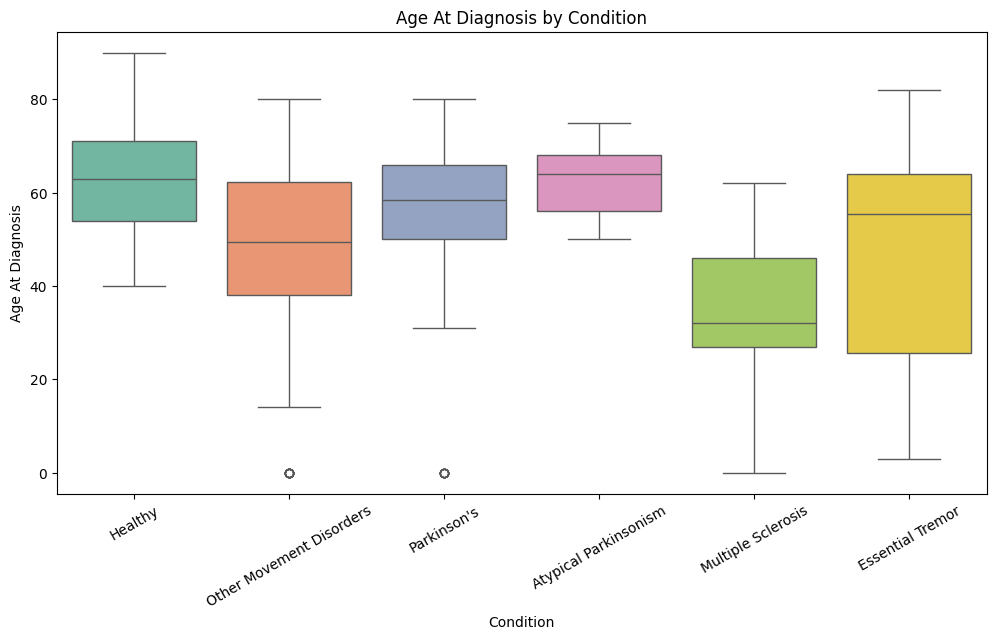

In [ ]:
#group by patient_id and get the first value of each column

df_grouped = df.groupby("Patient_id").agg({
    "Age": "first",
    "Gender": "first",
    "Condition": "first",
    "Age_At_Diagnosis": "first"

}).reset_index()

#plot Age at Diagnosis by condition by using Boxplot

plt.figure(figsize=(12,6))
sns.boxplot(data=df_grouped, x="Condition",y="Age_At_Diagnosis", hue="Condition",dodge=False,legend=False,palette="Set2")

#Add labels
plt.xlabel("Condition")
plt.ylabel("Age At Diagnosis")
plt.title("Age At Diagnosis by Condition")
plt.xticks(rotation=30)
plt.show();

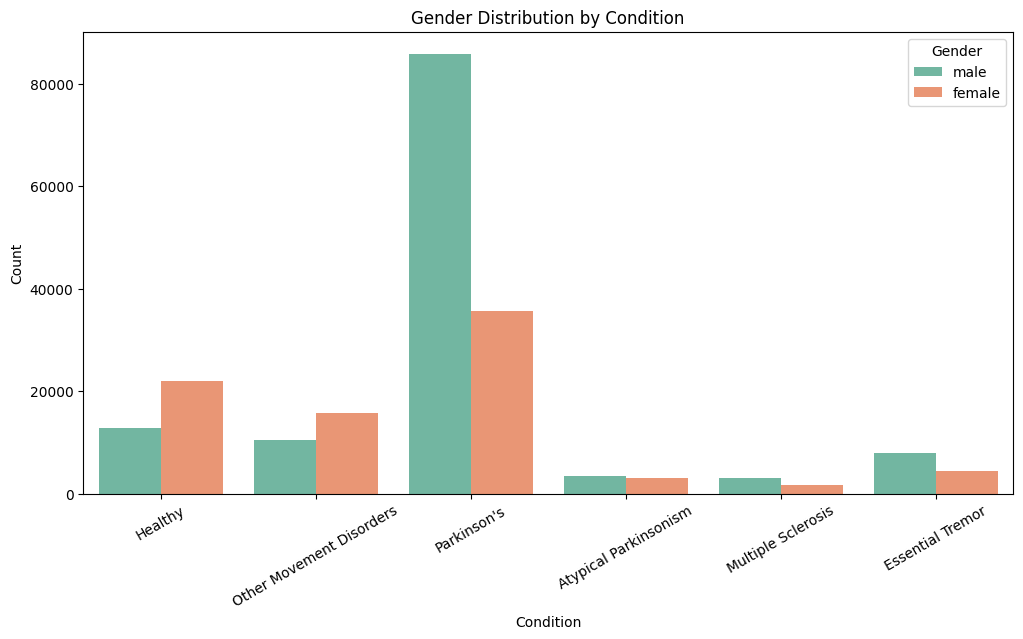

In [ ]:
#plot gender distribution by condition
plt.figure(figsize=(12,6))
sns.countplot(data=df, x="Condition",hue="Gender",palette="Set2")

#Add labels
plt.xlabel("Condition")
plt.ylabel("Count")
plt.title("Gender Distribution by Condition")
plt.xticks(rotation=30)
plt.show();

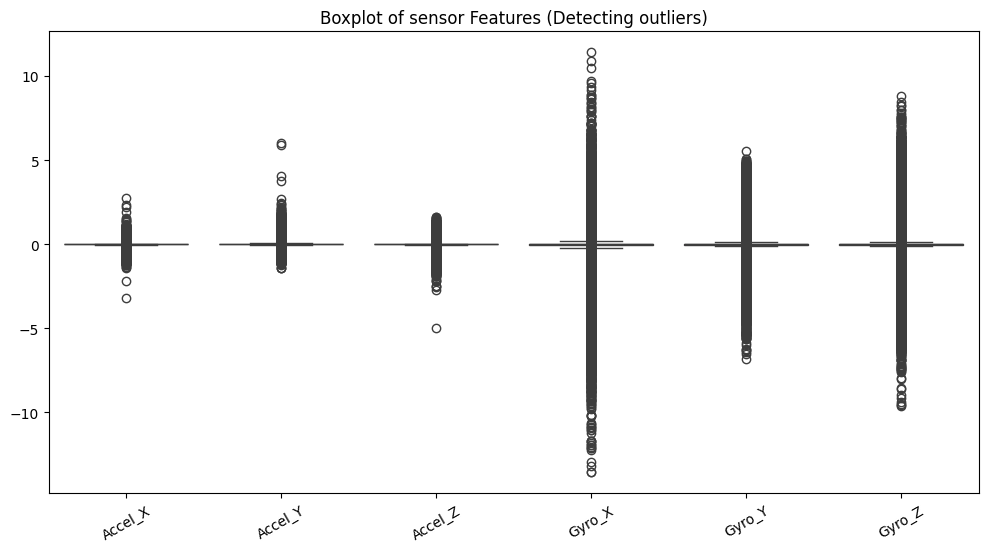

In [ ]:
#Boxplot for detecting outliers

#define sensor columns
sensor_columns= ["Accel_X", "Accel_Y", "Accel_Z", "Gyro_X", "Gyro_Y", "Gyro_Z"]

plt.figure(figsize=(12,6))
sns.boxplot(data=df[sensor_columns]) #sensor data columns
plt.title("Boxplot of sensor Features (Detecting outliers)")
plt.xticks(rotation=30)
plt.show();

**Remove Outliers if any**

In [ ]:
#remove outliers using z - score
#Compute Z scores
z_scores = np.abs(zscore(df[sensor_columns]))

#remove outliers where z score > 3 (outliers)
df = df[(z_scores < 3).all(axis=1)]

#shape after removing the outliers
print("Shape after removing the outliers",df.shape)



Shape after removing the outliers (187520, 17)


Normalize numeric Variables

In [ ]:
#remove rows where time==0.00 (smartwatch vibrations)
df = df[df["Time"] > 0.00].copy()

#normalize elaped time per (patient_id,Task) group
scalar_time = MinMaxScaler()
df["Normalized_Time"] = df.groupby(["Patient_id","Task"])["Time"].transform(lambda x: scalar_time.fit_transform(x.values.reshape(-1,1)).flatten())


In [ ]:
#Convert gender to binary values
df["Gender"] = df["Gender"].map({"male":0,"female":1})

In [ ]:
#Convert Handedness to binary values
df["Handedness"] = df["Handedness"].map({"right":0,"left":1})

In [ ]:
#filter only healthy and parkinsons conditions

df = df[df["Condition"].isin(["Healthy","Parkinson's"])].copy()

#Convert conditions to binary labels
df["Condition"] = df["Condition"].map({"Healthy":0, "Parkinson's":1})

In [ ]:
#drop unnecessary columsn

df.drop(columns="Age",inplace=True)

**Save Cleaned Data**

Mount the google drive to Collabe Notebook


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

#save the cleaned dataset
df.to_csv("/content/drive/MyDrive/Parkinson_prediction/Clean_Dataset.csv", index=False)

print("\nCleaned dataset saved as 'Clean_Dataset.csv'.")


Cleaned dataset saved as 'Clean_Dataset.csv'.


**Next steps**



*   Normalize features
*   split datasets
*   Train model




